# Tumor Growth Models with Treatment

## 1. Research Objective

We extend the classical Logistic and Gompertz tumor growth models
by introducing a time-dependent treatment term.

Our goals are to:
- Investigate how treatment affects tumor growth.
- Compare different treatment strengths and starting times.
- Evaluate the numerical accuracy and stability of different methods.

## 2. Mathematical Formulation

We introduce a time-dependent treatment term to the classical tumor growth models.

### 2.1 Logistic Model with Treatment

$$
\frac{dV}{dt}
= a_L V\left(1-\frac{V}{K}\right)-u(t)V
$$

### 2.2 Gompertz Model with Treatment

$$
\frac{dV}{dt}
= a_G e^{-\beta t}V-u(t)V
$$

### 2.3 Treatment Function

We assume that treatment starts at time $t_s$ and continues at a constant intensity:

$$
u(t)=
\begin{cases}
0, & t<t_s\\
\delta, & t\geq t_s
\end{cases}
$$

where:
- $V(t)$ is the tumor volume.
- $t_s$ is the treatment starting time.
- $\delta$ is the treatment-induced death rate.
- $K$ is the carrying capacity.

In [4]:
from scipy.integrate import solve_ivp
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

from mpl_toolkits.mplot3d import Axes3D

# Treatment parameters
ts = 20
delta = 0.1
# Initial conditions
V0 = 1.0
T = 60.0
plateau = 10.0

# Logistic parameters
a_L = 0.2 / (1 - V0 / plateau)
K = plateau

# Gompertz parameters
a_G = 0.2
beta = a_G / np.log(plateau / V0)

# Time points
t = np.linspace(0, T, 100)

print("Logistic growth rate:", a_L)
print("Gompertz beta:", beta)

def treatment(t):
    return delta if t >= ts else 0.0

def logistic_treatment(t, V):
    return a_L * V * (1 - V / K) - treatment(t) * V

def gompertz_treatment(t, V):
    return a_G * np.exp(-beta * t) * V - treatment(t) * V

Logistic growth rate: 0.22222222222222224
Gompertz beta: 0.08685889638065036


In [5]:
def solve_treatment(model):
    pre = solve_ivp(model, [0, ts], [V0], dense_output=True)
    post = solve_ivp(
        model, [ts, T], pre.y[:, -1],
        dense_output=True
    )

    return np.where(
        t < ts,
        pre.sol(np.minimum(t, ts))[0],
        post.sol(np.maximum(t, ts))[0]
    )

V_logistic_treat = solve_treatment(logistic_treatment)
V_gompertz_treat = solve_treatment(gompertz_treatment)

In [7]:
# Exact solutions without treatment
def logistic_exact(t):
    return K / (1 + (K / V0 - 1) * np.exp(-a_L * t))

def gompertz_exact(t):
    return V0 * np.exp(
        (a_G / beta) * (1 - np.exp(-beta * t))
    )

V_logistic = logistic_exact(t)
V_gompertz = gompertz_exact(t)

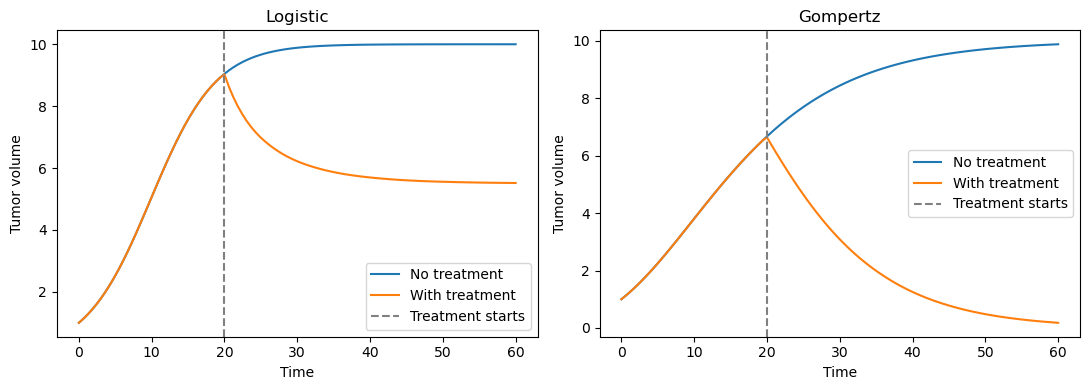

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, name, V_no, V_treat in zip(
    axes,
    ["Logistic", "Gompertz"],
    [V_logistic, V_gompertz],
    [V_logistic_treat, V_gompertz_treat]
):
    ax.plot(t, V_no, label="No treatment")
    ax.plot(t, V_treat, label="With treatment")
    ax.axvline(ts, color="gray", linestyle="--",
               label="Treatment starts")

    ax.set_title(name)
    ax.set_xlabel("Time")
    ax.set_ylabel("Tumor volume")
    ax.legend()

plt.tight_layout()
plt.show()

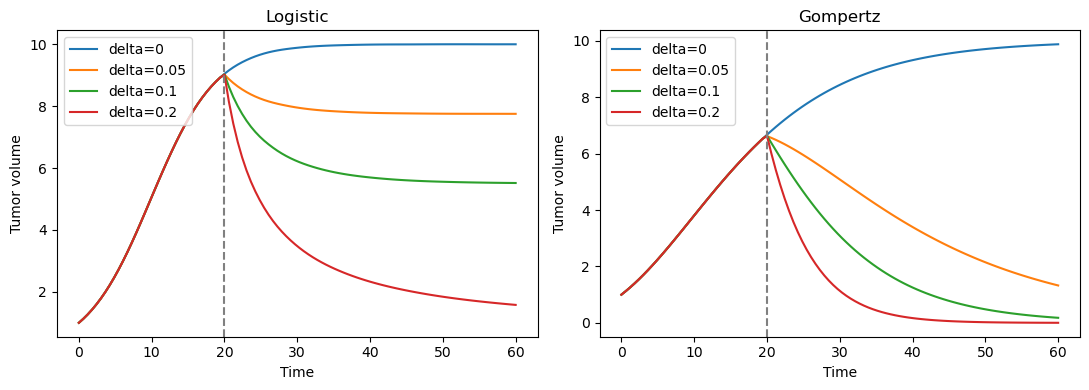

In [9]:
strengths = [0, 0.05, 0.1, 0.2]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for delta in strengths:
    V_L = solve_treatment(logistic_treatment)
    V_G = solve_treatment(gompertz_treatment)

    axes[0].plot(t, V_L, label=f"delta={delta}")
    axes[1].plot(t, V_G, label=f"delta={delta}")

for ax, title in zip(axes, ["Logistic", "Gompertz"]):
    ax.axvline(ts, color="gray", linestyle="--")
    ax.set_title(title)
    ax.set_xlabel("Time")
    ax.set_ylabel("Tumor volume")
    ax.legend()

plt.tight_layout()
plt.show()

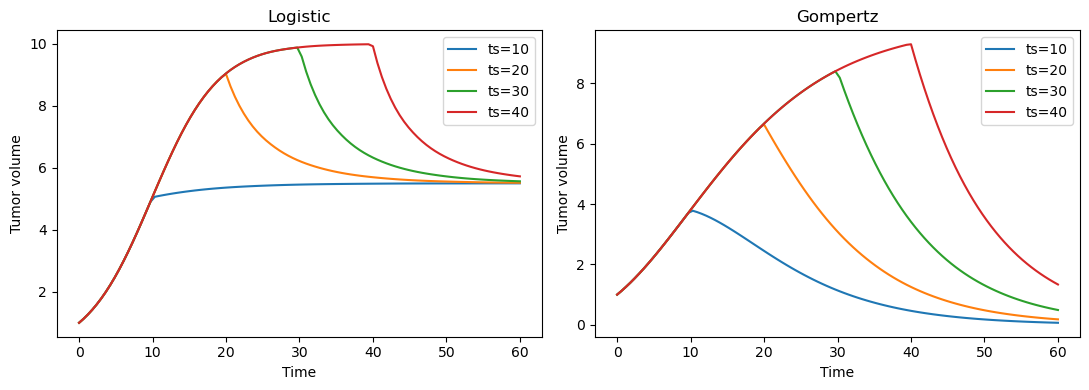

In [10]:
# Fix treatment strength
delta = 0.1

start_times = [10, 20, 30, 40]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ts in start_times:
    V_L = solve_treatment(logistic_treatment)
    V_G = solve_treatment(gompertz_treatment)

    axes[0].plot(t, V_L, label=f"ts={ts}")
    axes[1].plot(t, V_G, label=f"ts={ts}")

for ax, title in zip(axes, ["Logistic", "Gompertz"]):
    ax.set_title(title)
    ax.set_xlabel("Time")
    ax.set_ylabel("Tumor volume")
    ax.legend()

plt.tight_layout()
plt.show()